# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import BijieLandslideDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/bijie_landslide/images/",
    "csv_file": "./data/bijie_landslide/images/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = BijieLandslideDataset(dataset_config)

## Show images from the dataset

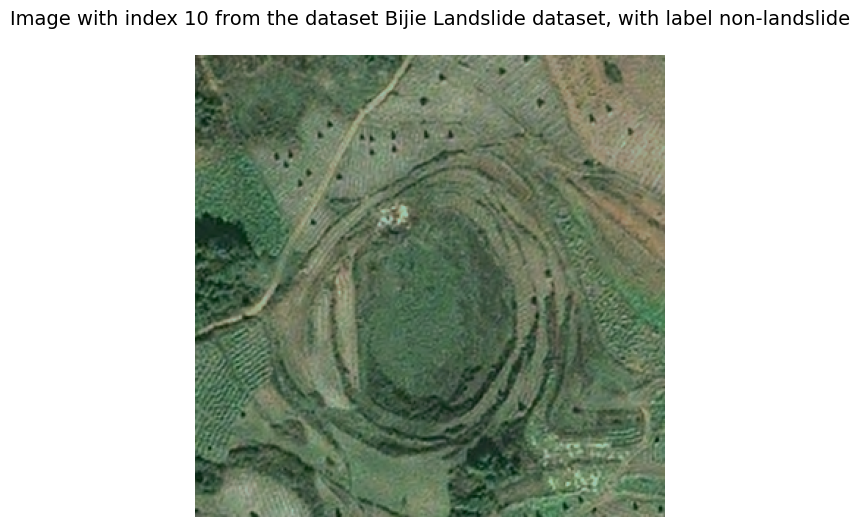

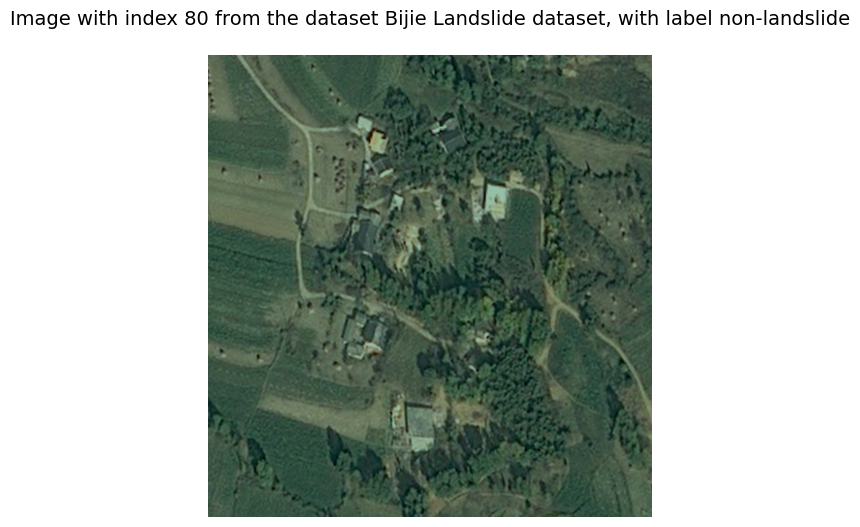

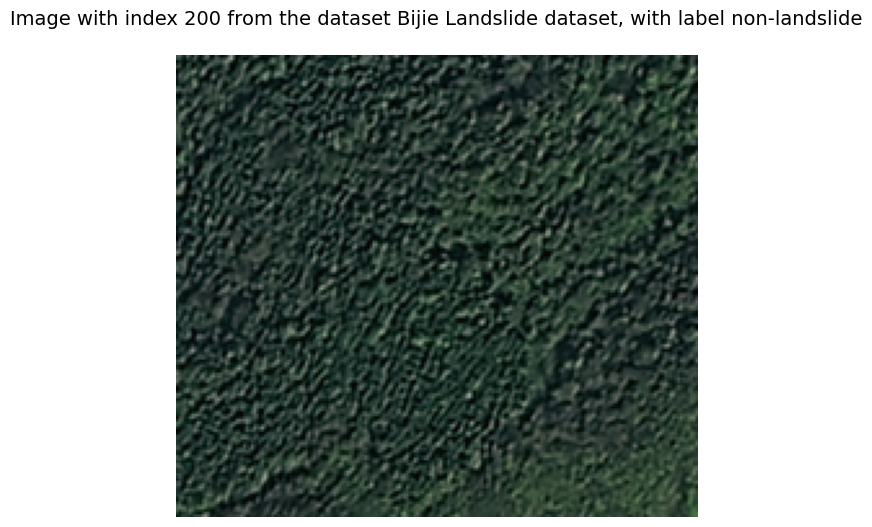

In [9]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

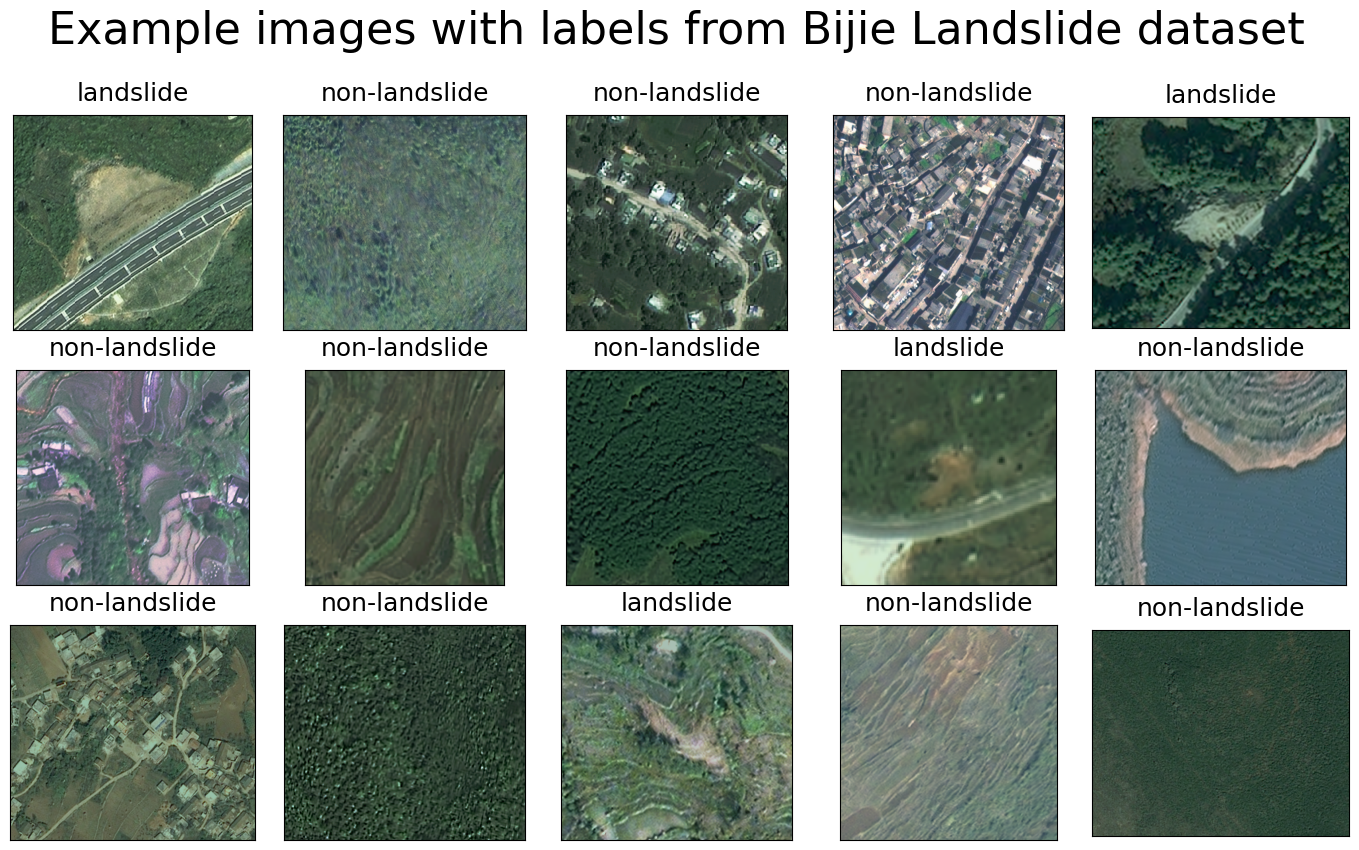

In [10]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [11]:
dataset.show_samples()

,File name,Label
0,landslide/ny003.png,landslide
1,non-landslide/fyb1213.png,non-landslide
2,landslide/df020.png,landslide
3,landslide/hz007.png,landslide
4,non-landslide/fyb102.png,non-landslide
5,non-landslide/fyb727.png,non-landslide
6,non-landslide/fyb1358.png,non-landslide
7,non-landslide/fyb117.png,non-landslide
8,landslide/qx031.png,landslide
9,non-landslide/fyb1317.png,non-landslide


In [12]:
dataset.data_distribution_table()

,Label,Count
0,landslide,620
1,non-landslide,1599


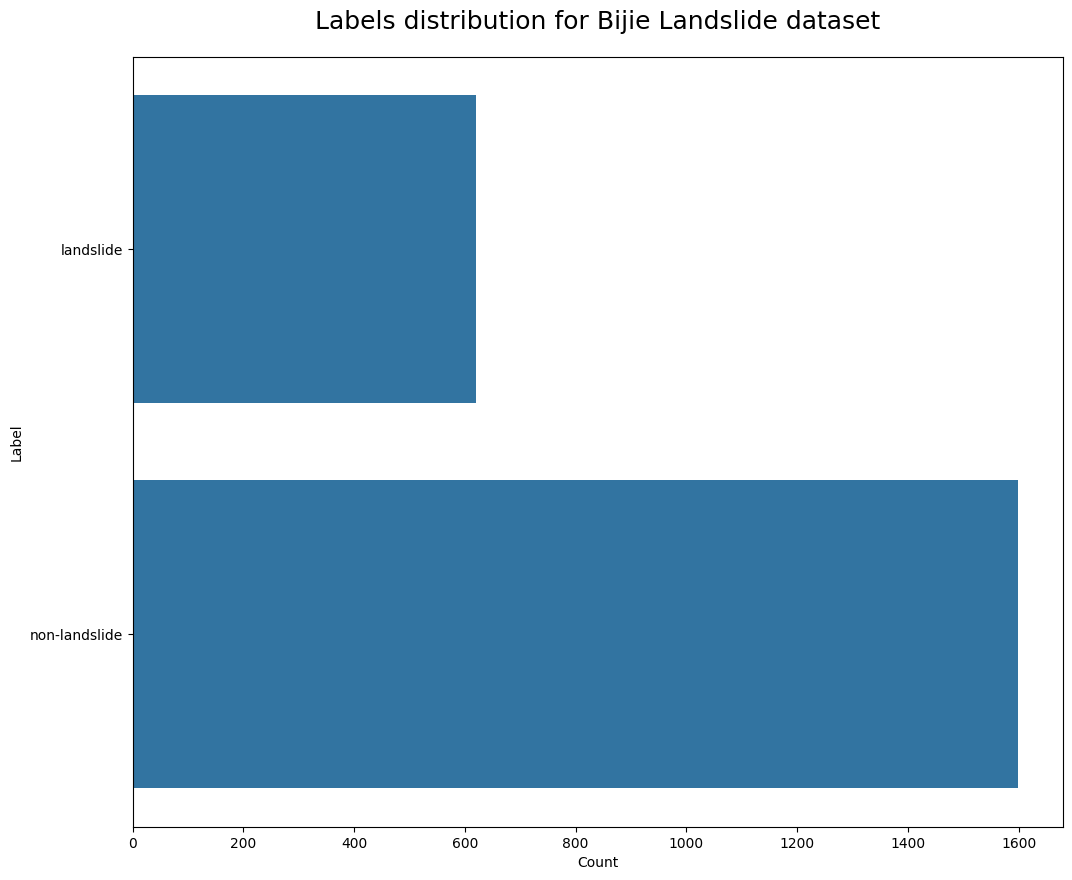

In [13]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/bijie_landslide/images/",
    "csv_file": "./data/bijie_landslide/images/train.csv",
}

train_dataset = BijieLandslideDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/bijie_landslide/images/",
    "csv_file": "./data/bijie_landslide/images/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = BijieLandslideDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(2219, 277)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/bijie_landslide/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 10:02:31,285 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 10:02:31,468 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [16]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 10:02:33,167 INFO Starting training.
training: 100%|██████████| 70/70 [00:40<00:00,  1.74it/s]
2025-05-20 10:03:13,773 INFO epoch: 1, time: 40, loss:  0.24277
testing on train set: 100%|██████████| 70/70 [00:14<00:00,  4.83it/s]
2025-05-20 10:03:30,449 INFO Accuracy:0.9738621000450653, Precision Micro:0.9738621000450653, Precision Macro:0.9688585142114929, Precision Weighted:0.9738015117201381, Precision per Class:[0.98006231 0.95765472], Recall Micro:0.9738621000450653, Recall Macro:0.9660634670862838, Recall Weighted:0.9738621000450653, Recall per Class:[0.98373984 0.9483871 ], F1_score Micro:0.9738621000450648, F1_score Macro:0.9674480036097498, F1_score Weighted:0.9738230294068801, F1_score per Class:[0.98189763 0.95299838]
testing on validation set: 100%|██████████| 9/9 [00:02<00:00,  4.20it/s]
2025-05-20 10:03:32,604 INFO Accuracy:0.9566787003610109, Precision Micro:0.9566787003610109, Precision Macro:0.9461196820944366, Precision Weighted:0.9576069657031272, Precision

0.011050652516503206

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/bijie_landslide/images/",
    "csv_file": "./data/bijie_landslide/images/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = BijieLandslideDataset(test_dataset_config)
model_path = "./data/experiments/bijie_landslide/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 10:11:51,100 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/bijie_landslide/checkpoint.pth.tar
2025-05-20 10:11:52,036 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/bijie_landslide/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 18/18 [00:02<00:00,  7.65it/s]


[{'Accuracy': 0.9855595667870036},
 {'Precision Micro': 0.9855595667870036,
  'Precision Macro': 0.9789769277474195,
  'Precision Weighted': 0.9855595667870036,
  'Precision per Class': array([0.99074074, 0.96721311])},
 {'Recall Micro': 0.9855595667870036,
  'Recall Macro': 0.9789769277474195,
  'Recall Weighted': 0.9855595667870036,
  'Recall per Class': array([0.99074074, 0.96721311])},
 {'F1_score Micro': 0.9855595667870031,
  'F1_score Macro': 0.978976927747419,
  'F1_score Weighted': 0.985559566787003,
  'F1_score per Class': array([0.99074074, 0.96721311])}]

## Predictions

2025-05-20 10:13:12,913 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/bijie_landslide/checkpoint.pth.tar
2025-05-20 10:13:13,641 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/bijie_landslide/checkpoint.pth.tar at epoch 11


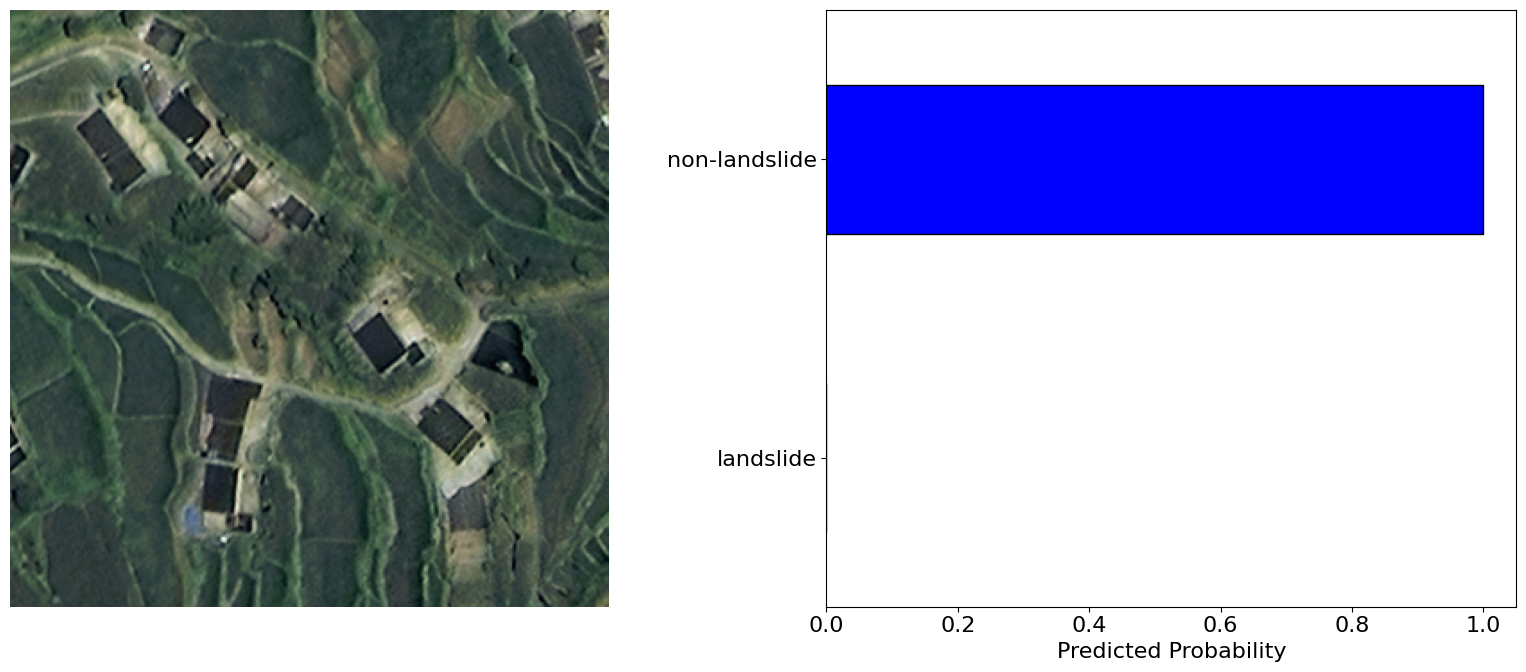

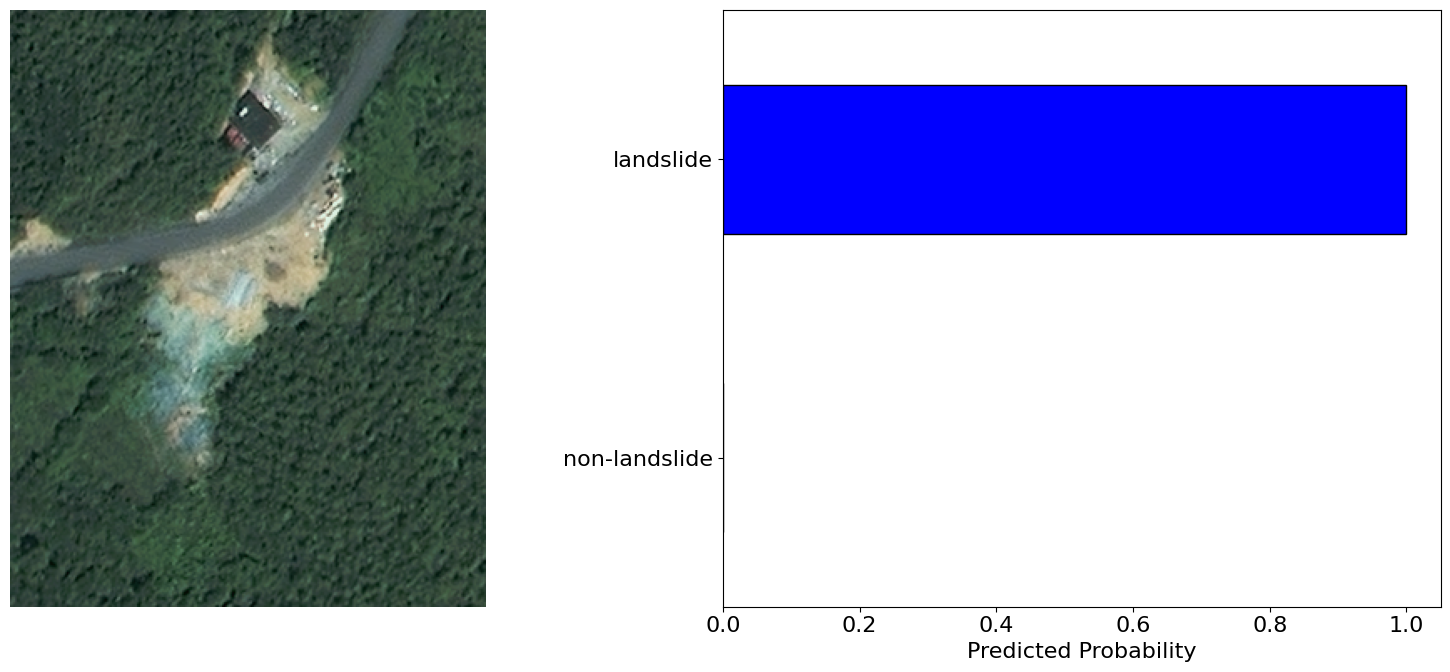

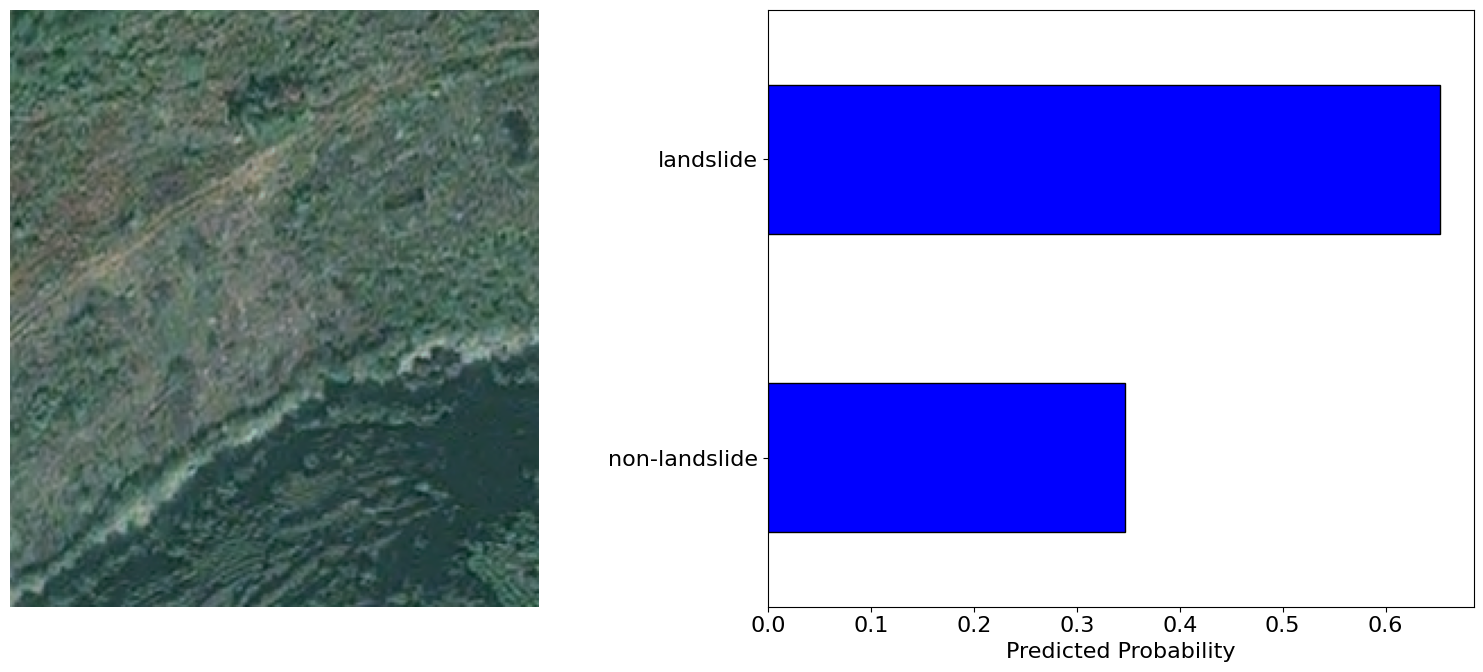

In [ ]:
labels = ["non-landslide","landslide"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/bijie_landslide/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/bijie_landslide/images/non-landslide/fyb969.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/bijie_landslide/images/landslide/js058.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/bijie_landslide/images/landslide/wn050.png')
fig = model.predict_image(image, labels, transform)